# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [62]:
# importar librerías
import pandas as pd
df = pd.read_csv("/datasets/plans.csv")
import pandas as pd
df = pd.read_csv("/datasets/users_latam.csv")
import pandas as pd
df = pd.read_csv("/datasets/usage.csv")

In [63]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv("/datasets/users_latam.csv")#completa el código
usage = pd.read_csv("/datasets/usage.csv")#completa el código

In [64]:

# mostrar las primeras 5 filas de plans
plans.head(5)

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [65]:
# mostrar las primeras 5 filas de users
users.head(5)

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [66]:
# mostrar las primeras 5 filas de usage
usage.head(5)

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [67]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage",usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [68]:
# inspección de plans con .info()
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [69]:
# inspección de users con .info()
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [70]:
# inspección de usage con .info()
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [71]:

# cantidad de nulos para users
print("Valores ausentes en users:")# Cantidad de valores nulos)
print(users.isna().sum())
# Proporción de valores nulos)



Valores ausentes en users:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64


In [72]:
# cantidad de nulos para usage

print("\nValores ausentes en usage:")
print(usage.isna().sum())


Valores ausentes en usage:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64


✍️ **Comentario**: 
Se identificaron datos faltantes en date, duration y length, principalmente en las dos últimas columnas. Para date, revisaría si se pueden recuperar los registros originales. En duration y length, investigaría por qué faltan tantos datos antes de decidir cómo tratarlos. 

💡 **Nota:** Justifica tus decisiones brevemente (1 línea por caso).
* Hint:Por el momento, conservaría estas columnas y evitaría eliminar información que podría ser útil. Las columnas id, user_id y type están completas y no necesitan ajustes por valores ausentes.
* 
 - Si una columna tiene **más del 80–90% de nulos**, normalmente se **ignora o elimina**.  
 - Si tiene **entre 5% y 30%**, generalmente se **investiga para imputar o dejar como nulos**.  
 - Si es **menor al 5%**, suele ser un caso simple de imputación o dejar como nulos. 
 
 ---

**Valores nulos**  
- ¿Qué columnas tienen valores faltantes y en qué proporción?
date: investigar e imputar solo si es posible recuperar la fecha correcta. Tiene únicamente un 0.13 % de valores ausentes, pero no debemos inventar fechas.
duration: investigar antes de imputar. Tiene un 55.19 % de valores ausentes; sustituirlos automáticamente por el promedio podría distorsionar el análisis.
length: investigar antes de imputar. Tiene un 44.74 % de valores ausentes; debemos comprender por qué faltan antes de decidir cómo tratarlos.
id, user_id y type: conservar sin tratamiento por valores ausentes, ya que no presentan ninguno. 
- 
- Indica qué harías: ¿imputar, eliminar, ignorar?
 El análisis de usage muestra valores faltantes en las columnas date (0.13 %), duration (55.19 %) y length (44.74 %). En date, investigaría si es posible recuperar las fechas originales. En duration y length, analizaría las causas y el patrón de ausencia antes de decidir si conviene imputar o conservar los valores nulos. No eliminaría estas columnas automáticamente, ya que podrían ser importantes para el análisis. Las columnas id, user_id y type no presentan valores faltantes, por lo que no requieren tratamiento.
- 

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [73]:



# explorar columnas numéricas de users
print(users.columns)
print(users.describe())

Index(['user_id', 'first_name', 'last_name', 'age', 'city', 'reg_date', 'plan',
       'churn_date'],
      dtype='object')
            user_id          age
count   4000.000000  4000.000000
mean   11999.500000    33.739750
std     1154.844867   123.232257
min    10000.000000  -999.000000
25%    10999.750000    32.000000
50%    11999.500000    47.000000
75%    12999.250000    63.000000
max    13999.000000    79.000000




- La columna `user_id`contiene 4,000 registros, con identificadores que van del 10,000 al 13,999. No presenta valores ausentes. Aunque el promedio es 11,999.5, este dato no tiene una interpretación estadística relevante, ya que los números funcionan como identificadores únicos de los usuarios.
- La columna `age` La columna age contiene 4,000 registros y tiene una edad promedio de 33.74 años, mientras que la mediana es de 47 años. Sin embargo, el valor mínimo es -999, lo que indica la posible presencia de un valor centinela que debe investigarse y tratarse antes de interpretar las estadísticas.



In [74]:
# explorar columnas numéricas de usage

print(usage.columns)
print(usage.describe())

Index(['id', 'user_id', 'type', 'date', 'duration', 'length'], dtype='object')
                id       user_id      duration        length
count  40000.00000  40000.000000  17924.000000  22104.000000
mean   20000.50000  12002.405975      5.202237     52.127398
std    11547.14972   1157.279564      6.842701     56.611183
min        1.00000  10000.000000      0.000000      0.000000
25%    10000.75000  10996.000000      1.437500     37.000000
50%    20000.50000  12013.000000      3.500000     50.000000
75%    30000.25000  13005.000000      6.990000     64.000000
max    40000.00000  13999.000000    120.000000   1490.000000



- Las columnas `id` y `user_id`...Haz doble clic en este bloque y escribe quLas columnas id y user_id contienen 40,000 registros cada una y no presentan valores ausentes. La columna id identifica cada registro, con valores del 1 al 40,000. La columna user_id identifica a los usuarios, con valores entre 10,000 y 13,999. é ves.
- Las columnas ...
La columna duration contiene 17,924 valores registrados, con un promedio de 5.20 y una mediana de 3.5. Su valor máximo es 120, mientras que el mínimo es 0. La diferencia entre el promedio y la mediana sugiere que algunos valores altos podrían influir en el promedio.

La columna length contiene 22,104 valores registrados, con un promedio de 52.13 y una mediana de 50. El valor máximo es 1,490, considerablemente superior al tercer cuartil de 64, por lo que conviene investigar si existen valores extremos.

Ambas columnas presentan una cantidad importante de valores ausentes: duration tiene 22,076 y length tiene 17,896. Es necesario analizar estos valores antes de decidir cómo tratarlos.

In [75]:

# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"La columna {col}:")
    print(users[col].value_counts())
    print()

La columna city:
Bogotá      808
CDMX        730
Medellín    616
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

La columna plan:
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` contine Bogotá, CDMX, Medellín, GDL,Cali,MTY
- La columna `plan` Basico,Premium

In [76]:

# explorar columna categórica de usage
columnas_usage=['type']# completa el código

for col in columnas_usage:
    print(usage[col].value_counts())


text    22092
call    17908
Name: type, dtype: int64


- La columna `type` text , Call


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?
- En la columna city encontré 96 registros con el símbolo ?, que representa un valor desconocido o inválido. En la columna plan se identificaron dos categorías: Basico y Premium. En la columna type aparecen las categorías text y call, que representan los tipos de servicio.
- 
- ¿Qué acción tomarías?
- Recomendaría reemplazar los valores ? de la columna city por valores ausentes (NaN) para identificarlos correctamente. Después, evaluaría si es posible recuperar las ciudades originales o si conviene mantenerlos como valores ausentes. También verificaría que las categorías de plan y type sean válidas antes de continuar con el análisis.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [77]:

# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce') # completa el código


In [78]:

# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'], errors='coerce')# completa el códig


In [79]:
# Revisar los años presentes en `reg_date` de users
users["reg_date"] = pd.to_datetime(users["reg_date"], errors="coerce", utc=True)
print(users["reg_date"].dt.year.value_counts().sort_index())

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64


En `reg_date`, ... haz doble clic en este bloque y escribe qué ves
Observo que la mayoría de los registros se concentran entre 2022 y 2024, con cantidades muy similares: 1,314 registros en 2022, 1,316 en 2023 y 1,330 en 2024. Sin embargo, en 2026 solamente aparecen 40 registros, lo que representa una diferencia considerable respecto a los años anteriores.

In [80]:

# Revisar los años presentes en `date` de usage
usage["date"] = pd.to_datetime(usage["date"], errors="coerce", utc=True)
print(usage["date"].dt.year.value_counts().sort_index())


2024.0    39950
Name: date, dtype: int64


En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas
Al revisar la columna date, identifiqué que los 39,950 registros corresponden al año 2024. No se observan registros de otros años, por lo que no es posible realizar comparaciones temporales entre diferentes años con los datos disponibles.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:

**Fechas fuera de rango**  
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos)
- Al revisar las fechas de los DataFrames users y usage, observé que en users, la columna reg_date contiene registros de 2022, 2023, 2024 y 2026. En usage, la columna date contiene 39,950 registros correspondientes únicamente a 2024. Con los resultados disponibles, no puedo confirmar la existencia de años imposibles; sin embargo, recomendaría verificar si las fechas de 2026 son válidas y si existen registros de otros años que no se hayan cargado.
- ¿Qué harías con ellas?
- Revisaría las fechas anteriores a un periodo razonable y las posteriores a la fecha de referencia del análisis. Si encuentro fechas imposibles o incorrectas, investigaría su origen y las corregiría si puedo recuperar el dato verdadero. Si no es posible validarlas, las convertiría en valores ausentes (NaT) para evitar que afecten el análisis.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [81]:

# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()


count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [82]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)
# Verificar cambios
print(users['city'].isna().sum())


565


In [83]:

# Marcar fechas futuras como NA para reg_date
users['reg_date'] = pd.to_datetime(users['reg_date'], errors='coerce', utc=True)
fecha_actual = pd.Timestamp.now(tz='UTC')

users.loc[users['reg_date'] > fecha_actual, 'reg_date'] = pd.NaT
# Verificar cambios
print(users['reg_date'].isna().sum())
# Verificar cambios



0


### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [84]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration_missing'] = usage['duration'].isna()
print(usage['duration_missing'].value_counts())
print(usage.groupby('type')['duration_missing'].mean() * 100)

True     22076
False    17924
Name: duration_missing, dtype: int64
type
call     0.000000
text    99.927576
Name: duration_missing, dtype: float64


In [85]:
# Verificación MAR en usage (Missing At Random) para length
usage['length_missing'] = usage['length'].isna()
print(usage['length_missing'].value_counts())
print(usage.groupby('type')['length_missing'].mean() * 100)

False    22104
True     17896
Name: length_missing, dtype: int64
type
call    99.932991
text     0.000000
Name: length_missing, dtype: float64


Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length
Al analizar los valores ausentes en el DataFrame usage, observé que la columna duration presenta 22,076 valores nulos y 17,924 registros con valores disponibles. Al comparar los datos por tipo de uso, encontré que el 99.93 % de los mensajes (text) no tienen un valor en duration, mientras que las llamadas (call) no presentan valores ausentes en esta columna.

En la columna length, identifiqué 17,896 valores nulos. La ausencia de datos se concentra en las llamadas (call), con un 99.93 % de valores ausentes, mientras que los mensajes (text) no presentan valores ausentes en esta columna.

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [86]:

# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby("user_id").agg({
    "is_text": "sum",
    "is_call": "sum",
    "duration": "sum"
}).reset_index()

# observar resultado
usage_agg.head(3)


,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [87]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [88]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")
user_profile.head(5)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [89]:
# Resumen estadístico de las columnas numéricas
user_profile.describe()

,user_id,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,3999.000000,3999.000000,3999.000000
mean,11999.500000,48.136000,5.524381,4.478120,23.317054
std,1154.844867,17.689919,2.358416,2.144238,18.168095
min,10000.000000,18.000000,0.000000,0.000000,0.000000
25%,10999.750000,33.000000,4.000000,3.000000,11.120000
50%,11999.500000,48.000000,5.000000,4.000000,19.780000
75%,12999.250000,63.000000,7.000000,6.000000,31.415000
max,13999.000000,79.000000,17.000000,15.000000,155.690000


In [90]:
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)

Basico     64.875
Premium    35.125
Name: plan, dtype: float64


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [91]:
import seaborn as sns
import matplotlib.pyplot as plt

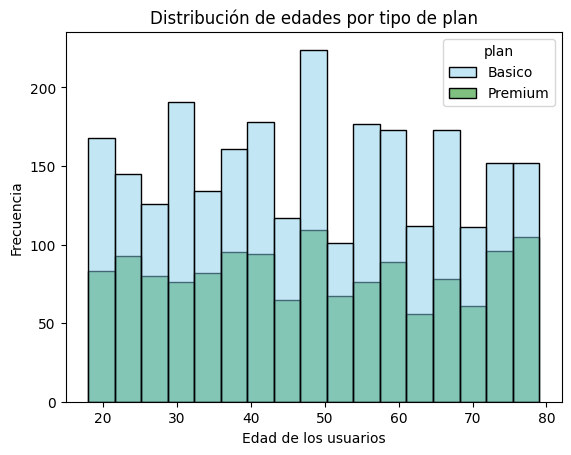

In [92]:
# Histograma para visualizar la edad (age)

sns.histplot(
    data=user_profile,
    x='age',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de edades por tipo de plan')
plt.xlabel('Edad de los usuarios')
plt.ylabel('Frecuencia')
plt.show()



💡Insights: 
- Distribución ...

Distribución: Las edades de los usuarios abarcan aproximadamente de los 18 a los 79 años. La distribución de ambos planes presenta usuarios en todos los rangos de edad observados.
Comparación por plan: Se observa una mayor frecuencia de usuarios del plan Básico que del plan Premium en la mayoría de los intervalos de edad. Sin embargo, ambos planes presentan una distribución de edades relativamente similar.
Forma de la distribución: No se observa una distribución claramente simétrica ni un sesgo pronunciado hacia la derecha o la izquierda. Las frecuencias fluctúan entre los diferentes rangos de edad, con algunos intervalos que presentan más usuarios que otros.


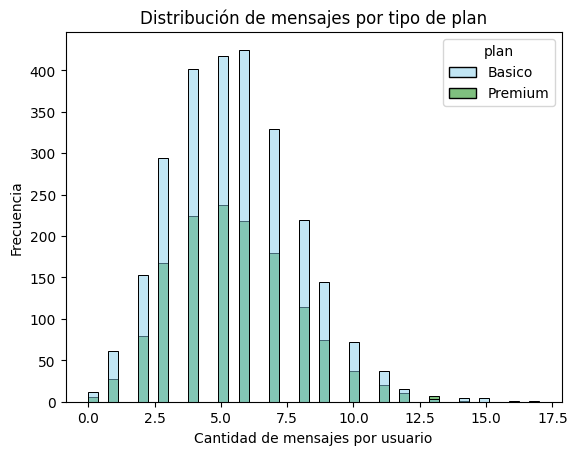

In [93]:
# Histograma para visualizar la cant_mensajes
sns.histplot(
    data=user_profile,
    x='cant_mensajes',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de mensajes por tipo de plan')
plt.xlabel('Cantidad de mensajes por usuario')
plt.ylabel('Frecuencia')
plt.show()



💡Insights: 
- Distribución ....
La cantidad de llamadas por usuario presenta una distribución sesgada hacia la derecha. La mayoría de los usuarios realiza entre 2 y 7 llamadas, mientras que una proporción menor realiza más de 8 llamadas.
Comparación por plan: Los usuarios del plan Básico presentan una mayor frecuencia en los diferentes rangos de llamadas que los usuarios Premium. Sin embargo, esto no significa necesariamente que realicen más llamadas por persona, ya que también debemos considerar cuántos usuarios hay en cada plan.
Valores extremos: Se observan algunos usuarios que realizan más de 10 llamadas, por lo que convendría revisar si estos valores representan comportamientos habituales o casos particulares


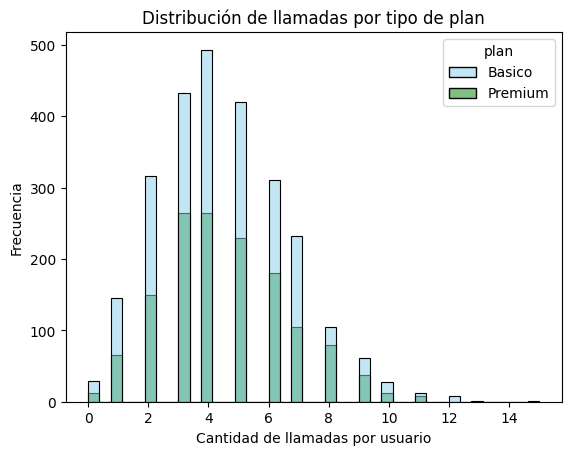

In [94]:
# Histograma para visualizar la cant_llamadas
sns.histplot(
    data=user_profile,
    x='cant_llamadas',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de llamadas por tipo de plan')
plt.xlabel('Cantidad de llamadas por usuario')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
 Distribución
 La cantidad de llamadas por usuario presenta una distribución sesgada hacia la derecha. La mayor concentración se encuentra entre 3 y 6 llamadas, mientras que la frecuencia disminuye conforme aumenta la cantidad de llamadas.
Comparación por plan: El plan Básico presenta una frecuencia mayor de usuarios en los distintos intervalos que el plan Premium. Sin embargo, para determinar qué plan tiene un mayor promedio de llamadas por usuario, sería necesario comparar las estadísticas de ambos grupos.
Valores extremos: Se observan pocos usuarios que realizan más de 10 llamadas. Recomendaría revisar estos casos para determinar si representan comportamientos habituales o valores atípicos.


- La cantidad de llamadas por usuario presenta una distribución sesgada hacia la derecha. La mayoría de los usuarios realiza entre 2 y 7 llamadas, mientras que una proporción menor realiza más de 8 llamadas.
Comparación por plan: Los usuarios del plan Básico presentan una mayor frecuencia en los diferentes rangos de llamadas que los usuarios Premium. Sin embargo, esto no significa necesariamente que realicen más llamadas por persona, ya que también debemos considerar cuántos usuarios hay en cada plan.
Valores extremos: Se observan algunos usuarios que realizan más de 10 llamadas, por lo que convendría revisar si estos valores representan comportamientos habituales o casos particulares

.

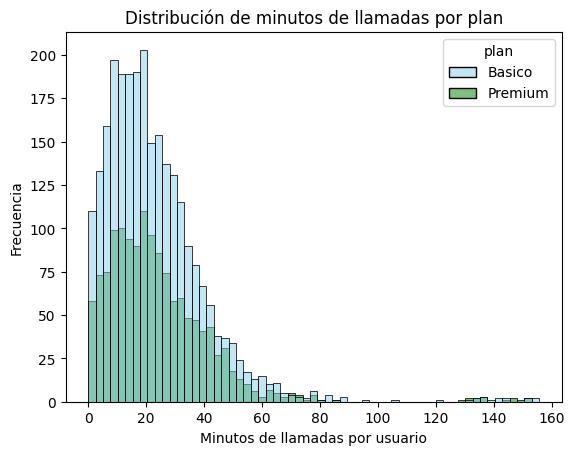

In [95]:
# Histograma para visualizar la cant_minutos_llamada

sns.histplot(
    data=user_profile,
    x='cant_minutos_llamada',
    hue='plan',
    palette=['skyblue', 'green']
)

plt.title('Distribución de minutos de llamadas por plan')
plt.xlabel('Minutos de llamadas por usuario')
plt.ylabel('Frecuencia')

plt.show()


💡Insights: 

Distribución: Los minutos de llamadas por usuario presentan una distribución sesgada hacia la derecha. La mayoría de los usuarios registra duraciones menores que los valores máximos observados.
Tendencia central: El promedio es de aproximadamente 23.32 minutos por usuario, mientras que la mediana es de 19.78 minutos. La diferencia entre ambas medidas es consistente con la presencia de algunos usuarios con duraciones elevadas.
Valores extremos: El máximo registrado es de 155.69 minutos. Este valor merece una revisión mediante el método IQR para determinar si se encuentra fuera de los límites estadísticos.
Comparación por plan: Para identificar qué plan registra una mayor duración de llamadas por usuario, es necesario comparar las estadísticas de cada plan y no basarse únicamente en las frecuencias del histograma.
Conclusión: La duración de las llamadas permite identificar diferentes patrones de consumo. Los registros extremos deben revisarse antes de decidir si es necesario realizar algún tratamiento.- ...

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

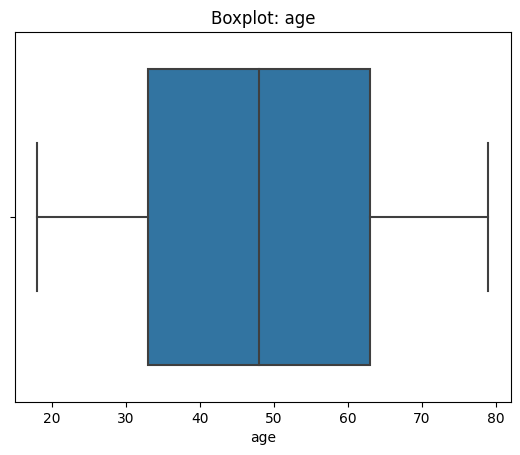

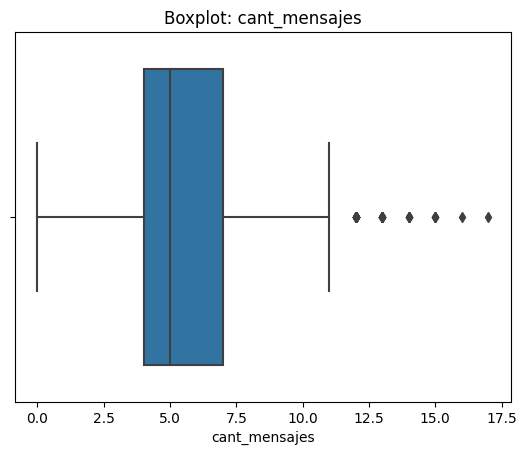

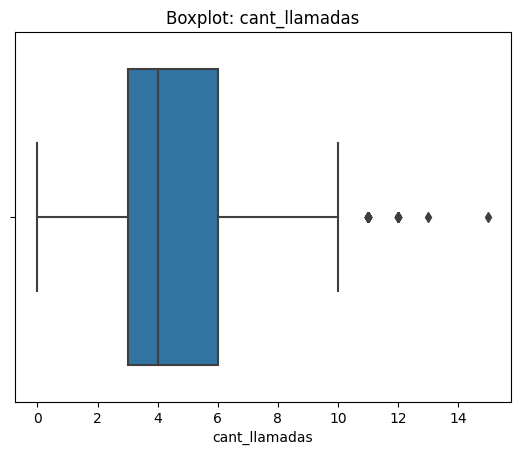

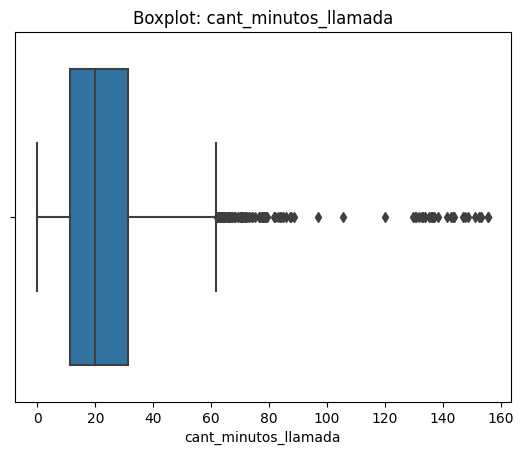

In [96]:

# Visualizando usando BoxPlot 
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(data=user_profile, x=col)
    plt.title(f'Boxplot: {col}')
    plt.show()


💡Insights: 
Edad (age): no se detectaron valores atípicos mediante el método IQR. Las edades se encuentran entre 18 y 79 años, dentro de los límites calculados.
Mensajes (cant_mensajes): se identificaron 46 posibles valores atípicos por encima del límite superior de 11.50 mensajes. Recomiendo conservarlos si corresponden a registros válidos.
Llamadas (cant_llamadas): se identificaron 30 posibles valores atípicos por encima del límite superior de 10.50 llamadas. Es conveniente revisar estos registros antes de decidir si requieren algún tratamiento.
Minutos de llamadas (cant_minutos_llamada): se identificaron 109 posibles valores atípicos por encima del límite superior de 61.86 minutos. Conviene revisar estos casos para determinar si representan duraciones válidas.

Conclusión: los valores atípicos detectados mediante IQR no deben eliminarse automáticamente. Primero hay que verificar si son errores o comportamientos reales de los usuarios.

In [97]:
# Calcular límites con el método IQR


columnas_limites = [
    'age',
    'cant_mensajes',
    'cant_llamadas',
    'cant_minutos_llamada'
]

for col in columnas_limites:
    Q1 = user_profile[col].quantile(0.25)
    Q3 = user_profile[col].quantile(0.75)
    IQR = Q3 - Q1

    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR

    outliers = user_profile[
        (user_profile[col] < limite_inferior) |
        (user_profile[col] > limite_superior)
    ]

    print(f'\nVariable: {col}')
    print(f'Límite inferior: {limite_inferior:.2f}')
    print(f'Límite superior: {limite_superior:.2f}')
    print(f'Cantidad de posibles outliers: {len(outliers)}')


Variable: age
Límite inferior: -12.00
Límite superior: 108.00
Cantidad de posibles outliers: 0

Variable: cant_mensajes
Límite inferior: -0.50
Límite superior: 11.50
Cantidad de posibles outliers: 46

Variable: cant_llamadas
Límite inferior: -1.50
Límite superior: 10.50
Cantidad de posibles outliers: 30

Variable: cant_minutos_llamada
Límite inferior: -19.32
Límite superior: 61.86
Cantidad de posibles outliers: 109


In [98]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,3999.000000,3999.000000,3999.000000
mean,48.136000,5.524381,4.478120,23.317054
std,17.689919,2.358416,2.144238,18.168095
min,18.000000,0.000000,0.000000,0.000000
25%,33.000000,4.000000,3.000000,11.120000
50%,48.000000,5.000000,4.000000,19.780000
75%,63.000000,7.000000,6.000000,31.415000
max,79.000000,17.000000,15.000000,155.690000


💡Insights: 
- cant_mensajes: mantener o no outliers, porqué?
- Los usuarios envían una media de 5.52 mensajes, con un máximo de 17 mensajes. Recomiendo mantener los posibles outliers, ya que una cantidad elevada de mensajes puede representar un comportamiento real de uso. Solo los corregiría si se identifican errores en los registros.
- cant_llamadas: mantener o no outliers, porqué?La media es de 4.48 llamadas por usuario y el máximo registrado es de 15. Recomiendo conservar los posibles outliers, porque algunos usuarios pueden realizar más llamadas que la mayoría. Antes de eliminarlos, verificaría que los valores sean válidos.
- 
- cant_minutos_llamada: mantener o no outliers, porqué?
- El promedio es de 23.32 minutos, mientras que el máximo alcanza los 155.69 minutos. Esta diferencia sugiere la presencia de posibles valores atípicos. Recomiendo revisar estos registros y mantenerlos si corresponden a un uso real, ya que eliminarlos podría distorsionar el análisis del comportamiento de los usuarios.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [99]:
# Crear columna grupo_uso


def clasificar_uso(row):
    # Verificar si faltan datos
    if pd.isna(row['cant_llamadas']) or pd.isna(row['cant_mensajes']):
        return 'Sin datos'

    if row['cant_llamadas'] < 5 and row['cant_mensajes'] < 5:
        return 'Bajo uso'

    elif row['cant_llamadas'] < 10 and row['cant_mensajes'] < 10:
        return 'Uso medio'

    else:
        return 'Alto uso'


user_profile['grupo_uso'] = user_profile.apply(
    clasificar_uso,
    axis=1
)

# Verificar resultados
print(user_profile['grupo_uso'].value_counts())


Uso medio    2943
Bajo uso      778
Alto uso      278
Sin datos       1
Name: grupo_uso, dtype: int64


In [100]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [101]:


# Crear columna grupo_edad
def clasificar_edad(row):
    if row['age'] < 30:
        return 'Joven'
    elif row['age'] < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile.apply(clasificar_edad, axis=1)




In [102]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00+00:00,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619+00:00,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239+00:00,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858+00:00,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478+00:00,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

In [ ]:

# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso')

plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

In [ ]:
# Visualización de los segmentos por edad

sns.countplot(data=user_profile, x='grupo_edad')

plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')

plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Valores ausentes: en usage, la columna date tiene 50 valores ausentes. La columna duration tiene 22,076 y la columna length tiene 17,896.
Valores centinela: se identificó el valor -999 en age, que fue sustituido por la mediana de las edades válidas.
Ciudades desconocidas: se encontraron 96 registros con ? en city. Estos se sustituyeron por valores ausentes, junto con los que ya existían.
Fechas: los registros de uso disponibles corresponden a 2024, mientras que las fechas de registro de los usuarios incluyen datos de 2022, 2023, 2024 y 2026. Conviene validar el periodo esperado para el proyecto.


🔍 **Segmentos por Edad**
La distribución muestra que el 50.45 % de los usuarios pertenece al grupo Adulto, el 30.55 % al grupo Adulto Mayor y el 19 % al grupo Joven.

Esto indica que los adultos constituyen el segmento más numeroso de la base de clientes. Sin embargo, todavía es necesario comparar sus patrones de consumo para determinar si existen diferencias relevantes entre los grupos.
📊 **Segmentos por Nivel de Uso**

Antes de corregir los usuarios sin datos, los resultados mostraban que el 73.58 % de los usuarios pertenecía al grupo Uso medio, el 19.45 % a Bajo uso y el 6.98 % a Alto uso.

Estos resultados deben actualizarse después de corregir la función de clasificación para distinguir a los usuarios sin datos de aquellos que realmente presentan un uso elevado.

➡️ Esto sugiere que ...

Las segmentaciones permiten describir la composición de los clientes por edad y nivel de actividad. No obstante, todavía no demuestran qué grupo genera más ingresos ni qué plan resulta más rentable.

💡 **Recomendaciones**

Mejorar la calidad de los datos y validar las fechas antes de continuar con análisis más avanzados.
Comparar el consumo de llamadas y mensajes entre los planes Básico y Premium.
Analizar la relación entre edad y nivel de uso para identificar diferencias entre segmentos.
Revisar los valores atípicos antes de decidir si es necesario modificarlos.
Utilizar los resultados para investigar oportunidades de mejora en los planes, sin asumir que un mayor uso implica necesariamente una mayor rentabilidad.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`